# Question 2: Copy-Mutate Algorithm with Addition and Deletion of Ingredients

### Algorithm Modifications & Rubric Compliance:
1. **Addition of Ingredients (4 marks):** Implemented via `add_ingredient()`, which selects a random ingredient from the Kitchen Basket ($KB$) not currently in the recipe and appends it, increasing the recipe size by 1.
2. **Deletion of Ingredients (3 marks):** Implemented via `delete_ingredient()`, which removes a randomly selected ingredient from the recipe while enforcing a minimum recipe size ($s_{\min} = 2$) so recipes remain valid.
3. **Recipe Size Distribution Plot with Mean and SD (2 marks):** Plots the emergent distribution of recipe sizes across 5 independent instances of cuisine evolution, highlighting the overall mean ($\mu$), standard deviation ($\sigma$), and per-size error bars.
4. **Normalized Frequency-Rank Distribution Plot (1 mark):** Plots the log-log normalized frequency-rank curves across the 5 random instances.

Running 5 instances of Copy-Mutate with Addition & Deletion...
Instance 1/5 complete: Mean Size = 9.00, SD = 1.66
Instance 2/5 complete: Mean Size = 9.11, SD = 1.59
Instance 3/5 complete: Mean Size = 9.29, SD = 1.65
Instance 4/5 complete: Mean Size = 9.03, SD = 1.59
Instance 5/5 complete: Mean Size = 9.08, SD = 1.61


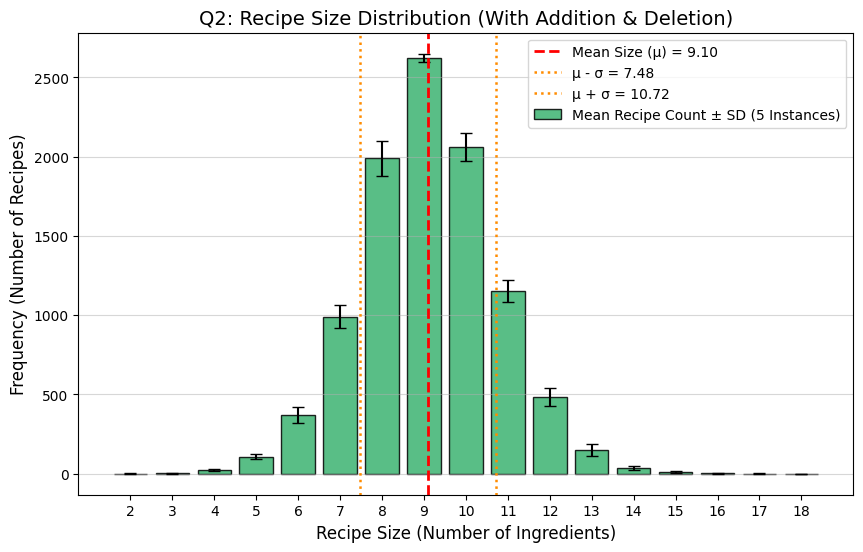

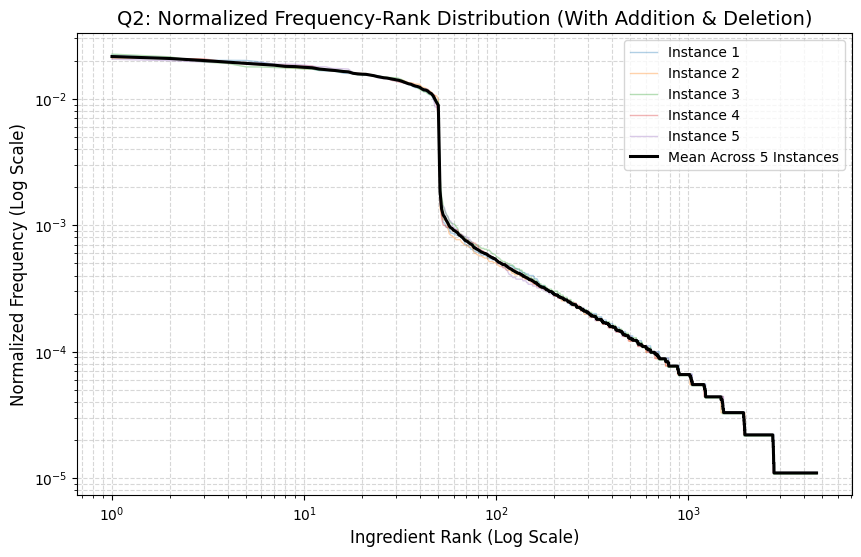

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
from collections import Counter

# ==========================================
# 1. Load Data & Setup Parameters
# ==========================================
df_raw = pd.read_csv("1b_extracted_ingredients.csv")
df_raw['Ingredient Name'] = df_raw['Ingredient Name'].fillna("").astype(str).str.strip()
df_raw = df_raw[df_raw['Ingredient Name'] != ""]

empirical_recipe_sizes = df_raw.groupby('Recipe ID').size()
s = int(round(empirical_recipe_sizes.mean()))
total_target_recipes = int(empirical_recipe_sizes.shape[0])

nature_basket = list(df_raw['Ingredient Name'].unique())
size_nb = len(nature_basket)

num_epochs = int(round(10))
n_r_t0 = int(round(200))
recipes_per_epoch = int(round((total_target_recipes - n_r_t0) / num_epochs))
initial_kb_size = int(round(50))
kb_step_per_epoch = int(round((size_nb - initial_kb_size) / num_epochs))

def initialize_primordial_cuisine(nb, n_r_0, recipe_size, kb_0_size):
    shuffled_nb = nb.copy()
    random.shuffle(shuffled_nb)
    kb = shuffled_nb[:kb_0_size]
    remaining_nb = shuffled_nb[kb_0_size:]

    cuisine_list = []
    cuisine_set = set()
    while len(cuisine_list) < n_r_0:
        recipe = sorted(random.sample(kb, recipe_size))
        recipe_key = frozenset(recipe)
        if recipe_key not in cuisine_set:
            cuisine_set.add(recipe_key)
            cuisine_list.append(recipe)
    return cuisine_list, cuisine_set, kb, remaining_nb

# ==========================================
# 2. Modification, Addition & Deletion Functions (7 marks)
# ==========================================
def modify_ingredient(recipe, kb):
    """Replaces a random ingredient in the recipe with a different one from KB."""
    new_rec = recipe.copy()
    rec_set = set(new_rec)
    while True:
        idx = random.randrange(len(new_rec))
        rec_ing = new_rec[idx]
        kb_ing = random.choice(kb)
        if kb_ing != rec_ing and kb_ing not in rec_set:
            new_rec[idx] = kb_ing
            break
    return new_rec

def add_ingredient(recipe, kb):
    """Rubric: Addition of ingredients (4 marks). Adds a new ingredient from KB."""
    new_rec = recipe.copy()
    rec_set = set(new_rec)
    if len(rec_set) >= len(kb):
        return modify_ingredient(new_rec, kb)
    while True:
        kb_ing = random.choice(kb)
        if kb_ing not in rec_set:
            new_rec.append(kb_ing)
            break
    return new_rec

def delete_ingredient(recipe, kb, min_size=2):
    """Rubric: Deletion of ingredients (3 marks). Deletes a random ingredient from the recipe."""
    new_rec = recipe.copy()
    if len(new_rec) <= min_size:
        return add_ingredient(new_rec, kb)
    idx = random.randrange(len(new_rec))
    new_rec.pop(idx)
    return new_rec

def mutate_with_add_delete(cuisine_list, kb):
    """Applies modification, addition, and deletion to a randomly chosen recipe."""
    chosen_recipe = random.choice(cuisine_list).copy()

    # Perform one of Modification, Addition, or Deletion with equal probability
    operation = random.choice(['modify', 'add', 'delete'])
    if operation == 'modify':
        mutated_recipe = modify_ingredient(chosen_recipe, kb)
    elif operation == 'add':
        mutated_recipe = add_ingredient(chosen_recipe, kb)
    else:
        mutated_recipe = delete_ingredient(chosen_recipe, kb, min_size=2)

    return mutated_recipe

def run_q2_simulation():
    cuisine_list, cuisine_set, kb, remaining_nb = initialize_primordial_cuisine(
        nature_basket, n_r_t0, s, initial_kb_size
    )

    for epoch in range(1, num_epochs + 1):
        if remaining_nb:
            add_count = min(kb_step_per_epoch, len(remaining_nb))
            kb.extend(remaining_nb[:add_count])
            remaining_nb = remaining_nb[add_count:]

        target_count = n_r_t0 + epoch * recipes_per_epoch
        while len(cuisine_list) < target_count:
            new_recipe = mutate_with_add_delete(cuisine_list, kb)
            recipe_key = frozenset(new_recipe)
            if recipe_key not in cuisine_set:
                cuisine_set.add(recipe_key)
                cuisine_list.append(new_recipe)

    return cuisine_list

# ==========================================
# 3. Run 5 Instances of Cuisine Evolution
# ==========================================
num_instances = 5
q2_instance_sizes = []
q2_instance_norm_freqs = []

print(f"Running {num_instances} instances of Copy-Mutate with Addition & Deletion...")
for inst in range(num_instances):
    final_cuisine = run_q2_simulation()
    sizes = [len(r) for r in final_cuisine]
    q2_instance_sizes.append(sizes)

    all_ings = [ing for r in final_cuisine for ing in r]
    counts = np.array(sorted(Counter(all_ings).values(), reverse=True))
    q2_instance_norm_freqs.append(counts / counts.sum())
    print(f"Instance {inst+1}/{num_instances} complete: Mean Size = {np.mean(sizes):.2f}, SD = {np.std(sizes):.2f}")

# ==========================================
# 4. Plot Recipe Size Distribution with Mean & SD (2 marks)
# ==========================================
all_sizes_flat = np.concatenate(q2_instance_sizes)
overall_mean = np.mean(all_sizes_flat)
overall_std = np.std(all_sizes_flat)

min_s, max_s = int(min(all_sizes_flat)), int(max(all_sizes_flat))
size_bins = np.arange(min_s, max_s + 1)
size_matrix = np.zeros((num_instances, len(size_bins)))

for i, sizes in enumerate(q2_instance_sizes):
    c = Counter(sizes)
    for j, val in enumerate(size_bins):
        size_matrix[i, j] = c.get(val, 0)

mean_counts = size_matrix.mean(axis=0)
std_counts = size_matrix.std(axis=0)

plt.figure(figsize=(10, 6))
plt.bar(size_bins, mean_counts, yerr=std_counts, capsize=4, color='mediumseagreen', edgecolor='black', alpha=0.85, label='Mean Recipe Count ± SD (5 Instances)')
plt.axvline(overall_mean, color='red', linestyle='--', linewidth=2, label=f'Mean Size (μ) = {overall_mean:.2f}')
plt.axvline(overall_mean - overall_std, color='darkorange', linestyle=':', linewidth=1.8, label=f'μ - σ = {overall_mean - overall_std:.2f}')
plt.axvline(overall_mean + overall_std, color='darkorange', linestyle=':', linewidth=1.8, label=f'μ + σ = {overall_mean + overall_std:.2f}')

plt.title('Q2: Recipe Size Distribution (With Addition & Deletion)', fontsize=14)
plt.xlabel('Recipe Size (Number of Ingredients)', fontsize=12)
plt.ylabel('Frequency (Number of Recipes)', fontsize=12)
plt.xticks(np.arange(min_s, max_s + 1, max(1, (max_s - min_s) // 15)))
plt.legend(fontsize=10)
plt.grid(axis='y', alpha=0.5)
plt.savefig("Q2_Recipe_Size_Distribution.png", dpi=300, bbox_inches='tight')
plt.show()

# ==========================================
# 5. Plot Normalized Frequency-Rank Distribution (1 mark)
# ==========================================
plt.figure(figsize=(10, 6))
min_ranks = min(len(nf) for nf in q2_instance_norm_freqs)
freq_matrix = np.array([nf[:min_ranks] for nf in q2_instance_norm_freqs])
ranks = np.arange(1, min_ranks + 1)

for i in range(num_instances):
    plt.loglog(ranks, freq_matrix[i], alpha=0.35, linewidth=1, label=f'Instance {i+1}')

plt.loglog(ranks, freq_matrix.mean(axis=0), color='black', linewidth=2.2, label='Mean Across 5 Instances')
plt.title('Q2: Normalized Frequency-Rank Distribution (With Addition & Deletion)', fontsize=14)
plt.xlabel('Ingredient Rank (Log Scale)', fontsize=12)
plt.ylabel('Normalized Frequency (Log Scale)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.savefig("Q2_Normalized_Frequency_Rank_Distribution.png", dpi=300, bbox_inches='tight')
plt.show()